In [ ]:
import os, subprocess
from pathlib import Path
from google.colab import drive

if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")
assert os.path.ismount("/content/drive"), "Drive is NOT mounted!"

BASE = Path("/content/drive/MyDrive/ai-medical-imaging")
SEG = BASE / "segmentation"
for d in ["", "models", "results"]:
    (SEG / d).mkdir(parents=True, exist_ok=True)

subprocess.run('pip -q install "monai[nibabel,tqdm]"', shell=True, check=True)
import monai, torch
print("MONAI", monai.__version__, "| GPU:", torch.cuda.is_available())

Mounted at /content/drive
MONAI 1.6.1 | GPU: True


In [ ]:
from monai.apps import download_and_extract

URL = "https://msd-for-monai.s3-us-west-2.amazonaws.com/Task09_Spleen.tar"
TAR = SEG / "Task09_Spleen.tar"
download_and_extract(URL, filepath=str(TAR), output_dir="/content/msd")

imgs = sorted(Path("/content/msd/Task09_Spleen/imagesTr").glob("spleen_*.nii.gz"))
print("CT volumes:", len(imgs))

Task09_Spleen.tar: 1.50GB [07:11, 3.73MB/s]                            
/usr/local/lib/python3.13/dist-packages/monai/apps/utils.py:273: UserWarning: No hash value provided for /tmp/tmpgpy5d30q/Task09_Spleen.tar; file integrity is NOT verified.
  if not check_hash(tmp_name, hash_val, hash_type):


2026-10-29 12:37:33,481 - INFO - Downloaded: /content/drive/MyDrive/ai-medical-imaging/segmentation/Task09_Spleen.tar
2026-10-29 12:37:33,482 - INFO - Writing into directory: /content/msd.
CT volumes: 41


In [ ]:
import json, time, random
import numpy as np
from monai.data import CacheDataset, DataLoader, decollate_batch
from monai.transforms import (Compose, LoadImaged, EnsureChannelFirstd, Orientationd,
                              Spacingd, ScaleIntensityRanged, CropForegroundd,
                              RandCropByPosNegLabeld, RandShiftIntensityd, AsDiscrete)
from monai.utils import set_determinism

set_determinism(seed=42)
ROOT = Path("/content/msd/Task09_Spleen")
files = [{"image": str(i), "label": str(ROOT / "labelsTr" / i.name)} for i in imgs]
random.Random(42).shuffle(files)
train_files, val_files, test_files = files[:29], files[29:35], files[35:]
json.dump({"train": train_files, "val": val_files, "test": test_files},
          open(SEG / "results" / "split.json", "w"), indent=1)
print("train/val/test volumes:", len(train_files), len(val_files), len(test_files))

base = [
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image", "label"]),
    Orientationd(keys=["image", "label"], axcodes="RAS"),
    Spacingd(keys=["image", "label"], pixdim=(1.5, 1.5, 2.0), mode=("bilinear", "nearest")),
    # CT soft-tissue window, scaled to 0-1
    ScaleIntensityRanged(keys="image", a_min=-57, a_max=164, b_min=0.0, b_max=1.0, clip=True),
    CropForegroundd(keys=["image", "label"], source_key="image", allow_smaller=True),
]
train_tf = Compose(base + [
    RandCropByPosNegLabeld(keys=["image", "label"], label_key="label",
                           spatial_size=(96, 96, 96), pos=1, neg=1, num_samples=4,
                           image_key="image", image_threshold=0),
    RandShiftIntensityd(keys="image", offsets=0.1, prob=0.5),
])
val_tf = Compose(base)

train_ds = CacheDataset(train_files, train_tf, cache_rate=1.0, num_workers=2)
val_ds = CacheDataset(val_files, val_tf, cache_rate=1.0, num_workers=2)
train_loader = DataLoader(train_ds, batch_size=2, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=1, num_workers=2)
print("Ready.")

/usr/local/lib/python3.13/dist-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


train/val/test volumes: 29 6 6


Loading dataset: 100%|██████████| 6/6 [00:16<00:00,  2.82s/it]

Ready.


In [ ]:
from monai.networks.nets import UNet
from monai.networks.layers import Norm
from monai.losses import DiceLoss
from monai.inferers import sliding_window_inference

device = torch.device("cuda")
model = UNet(spatial_dims=3, in_channels=1, out_channels=2,
             channels=(16, 32, 64, 128, 256), strides=(2, 2, 2, 2),
             num_res_units=2, norm=Norm.BATCH).to(device)
loss_fn = DiceLoss(to_onehot_y=True, softmax=True)
MAX_EPOCHS, VAL_EVERY = 150, 2
opt = torch.optim.Adam(model.parameters(), 1e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MAX_EPOCHS)
scaler = torch.amp.GradScaler("cuda")


def dice_score(pred, truth):
    p, t = (pred == 1), (truth == 1)
    return (2 * (p & t).sum() / (p.sum() + t.sum() + 1e-8)).item()


@torch.no_grad()
def validate(loader):
    model.eval()
    scores = []
    for b in loader:
        x, y = b["image"].to(device), b["label"].to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            out = sliding_window_inference(x, (96, 96, 96), 4, model)
        scores.append(dice_score(out.float().argmax(1, keepdim=True), y))
    return float(np.mean(scores))


LAST, BEST = SEG / "models" / "last.pt", SEG / "models" / "best_unet3d.pt"
start, best, history = 1, 0.0, []
if LAST.exists():
    ck = torch.load(LAST, map_location=device)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
    sched.load_state_dict(ck["sched"])
    start, best, history = ck["epoch"] + 1, ck["best"], ck["history"]
    print("Resuming from epoch", start)

for epoch in range(start, MAX_EPOCHS + 1):
    t0 = time.time()
    model.train()
    total, n = 0.0, 0
    for b in train_loader:
        x, y = b["image"].to(device), b["label"].to(device)
        opt.zero_grad()
        with torch.autocast("cuda", dtype=torch.float16):
            loss = loss_fn(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        total += loss.item(); n += 1
    sched.step()
    rec = dict(epoch=epoch, train_loss=total / n, val_dice=None)

    msg = ""
    if epoch % VAL_EVERY == 0 or epoch == MAX_EPOCHS:
        rec["val_dice"] = validate(val_loader)
        if rec["val_dice"] > best:
            best = rec["val_dice"]
            torch.save(model.state_dict(), BEST)
            msg = "  <- best, saved"
        history.append(rec)
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        epoch=epoch, best=best, history=history), LAST)
        json.dump(history, open(SEG / "results" / "history.json", "w"))
        print(f"Epoch {epoch:3d}/{MAX_EPOCHS} | loss {rec['train_loss']:.3f} | "
              f"val Dice {rec['val_dice']:.3f} | {time.time()-t0:.0f}s{msg}")
    else:
        history.append(rec)

print("Best validation Dice:", round(best, 4))

Epoch   2/150 | loss 0.537 | val Dice 0.052 | 9s  <- best, saved
Epoch   4/150 | loss 0.448 | val Dice 0.232 | 9s  <- best, saved
Epoch   6/150 | loss 0.363 | val Dice 0.231 | 10s
Epoch   8/150 | loss 0.352 | val Dice 0.305 | 9s  <- best, saved
Epoch  10/150 | loss 0.275 | val Dice 0.268 | 10s
Epoch  12/150 | loss 0.241 | val Dice 0.194 | 9s
Epoch  14/150 | loss 0.245 | val Dice 0.022 | 9s
Epoch  16/150 | loss 0.221 | val Dice 0.440 | 10s  <- best, saved
Epoch  18/150 | loss 0.283 | val Dice 0.677 | 9s  <- best, saved
Epoch  20/150 | loss 0.220 | val Dice 0.359 | 9s
Epoch  22/150 | loss 0.237 | val Dice 0.329 | 9s
Epoch  24/150 | loss 0.226 | val Dice 0.232 | 9s
Epoch  26/150 | loss 0.244 | val Dice 0.536 | 10s
Epoch  28/150 | loss 0.220 | val Dice 0.407 | 10s
Epoch  30/150 | loss 0.172 | val Dice 0.714 | 9s  <- best, saved
Epoch  32/150 | loss 0.223 | val Dice 0.413 | 10s
Epoch  34/150 | loss 0.201 | val Dice 0.783 | 9s  <- best, saved
Epoch  36/150 | loss 0.221 | val Dice 0.162 | 10s

Loading dataset: 100%|██████████| 6/6 [00:17<00:00,  2.86s/it]


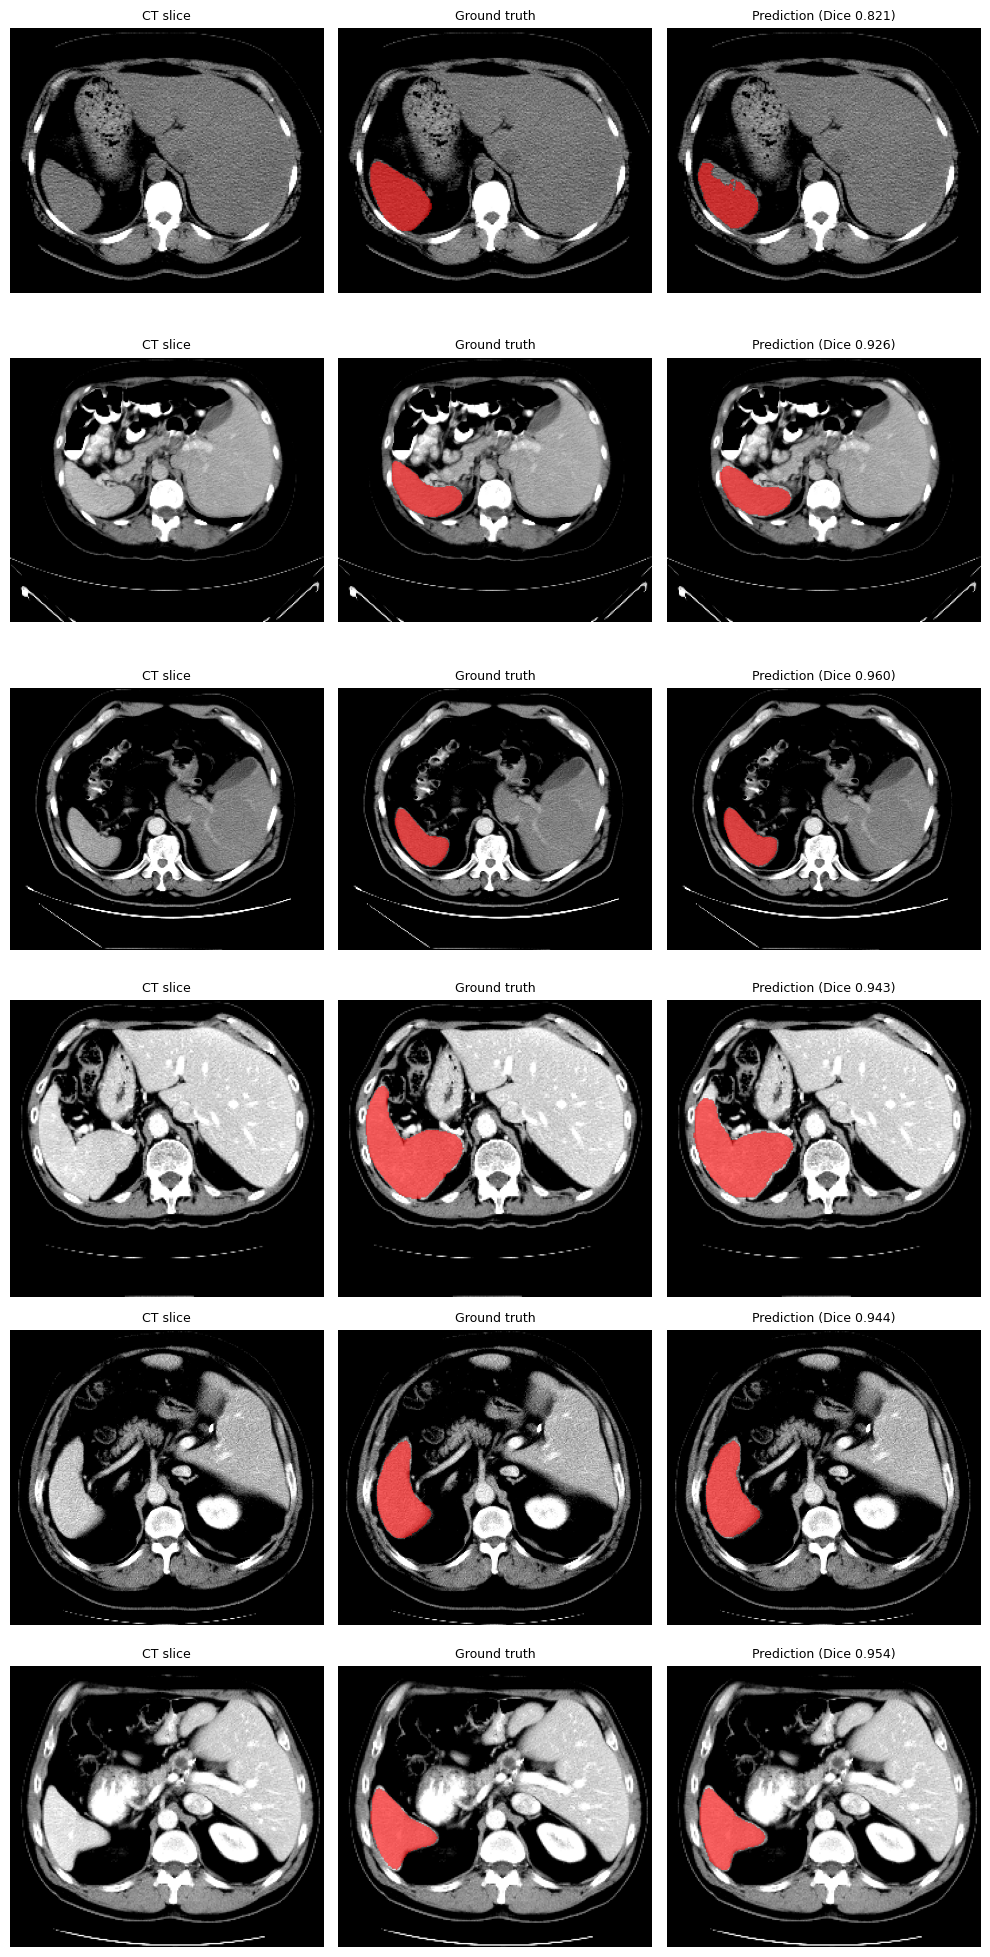

{
  "task": "Task09_Spleen",
  "model": "MONAI 3D UNet",
  "test_volumes": 6,
  "test_dice_mean": 0.9246535003185272,
  "test_dice_std": 0.04764619426395241,
  "test_dice_per_case": [
    0.8207,
    0.9263,
    0.9599,
    0.9431,
    0.9441,
    0.9538
  ],
  "best_val_dice": 0.9437868197758993
}


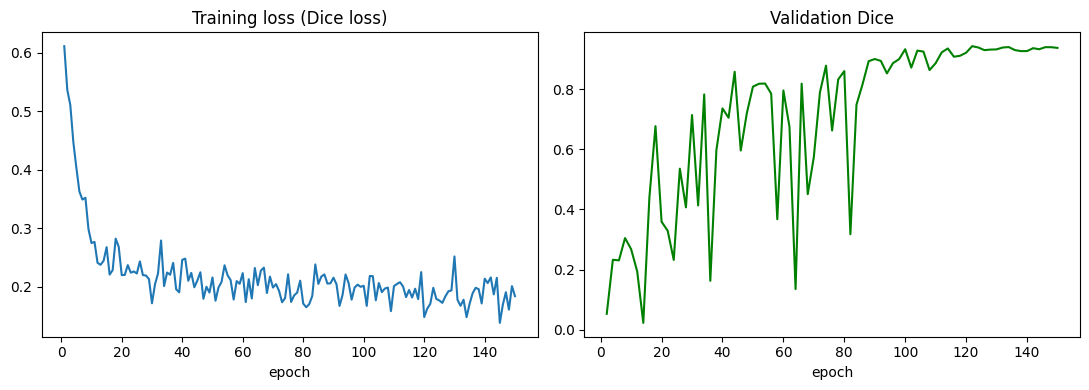

In [ ]:
import matplotlib.pyplot as plt

test_ds = CacheDataset(test_files, val_tf, cache_rate=1.0, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=1)
model.load_state_dict(torch.load(BEST, map_location=device)); model.eval()

cases = []
fig, axes = plt.subplots(len(test_files), 3, figsize=(10, 3.3 * len(test_files)))
with torch.no_grad():
    for i, b in enumerate(test_loader):
        x, y = b["image"].to(device), b["label"].to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            out = sliding_window_inference(x, (96, 96, 96), 4, model)
        pred = out.float().argmax(1, keepdim=True)
        d = dice_score(pred, y)
        cases.append(d)

        z = int(y[0, 0].sum(dim=(0, 1)).argmax())            # slice with the most spleen
        ct = x[0, 0, :, :, z].cpu().numpy().T
        gt = (y[0, 0, :, :, z] == 1).cpu().numpy().T
        pr = (pred[0, 0, :, :, z] == 1).cpu().numpy().T
        for ax, mask, title in zip(axes[i], [None, gt, pr],
                                   ["CT slice", "Ground truth", f"Prediction (Dice {d:.3f})"]):
            ax.imshow(ct, cmap="gray", origin="lower")
            if mask is not None:
                ax.imshow(np.ma.masked_where(~mask, mask), cmap="autumn", alpha=0.6, origin="lower")
            ax.set_title(title, fontsize=9); ax.axis("off")
plt.tight_layout()
plt.savefig(SEG / "results" / "segmentation_examples.png", dpi=110)
plt.show()

seg_metrics = dict(task="Task09_Spleen", model="MONAI 3D UNet", test_volumes=len(cases),
                   test_dice_mean=float(np.mean(cases)), test_dice_std=float(np.std(cases)),
                   test_dice_per_case=[round(c, 4) for c in cases], best_val_dice=float(best))
json.dump(seg_metrics, open(SEG / "results" / "metrics.json", "w"), indent=2)
print(json.dumps(seg_metrics, indent=2))

h = [r for r in history if r["val_dice"] is not None]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([r["epoch"] for r in history], [r["train_loss"] for r in history])
ax[0].set_title("Training loss (Dice loss)"); ax[0].set_xlabel("epoch")
ax[1].plot([r["epoch"] for r in h], [r["val_dice"] for r in h], color="green")
ax[1].set_title("Validation Dice"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(SEG / "results" / "segmentation_curves.png", dpi=110); plt.show()